# Cointegrated pairs 

This script in python aims to simulate a trading strategy of two cointegrated pairs.The stock's price of an asset, follows naturally a random walk ,th eprice fluctuates without any specified trend, so it's quite impossible to forecast future movements . Even though, when it's possible to find two assets which have a certain degree of correlation, the two assets will keep each one following random paths, but its distance will remain stationary. In other words, the movement of one asset will give a hint about the potential movements of the other asset , hence , if one can prove that two assets are cointegrated, a trading strategy can be implemented whenever an outlier difference between two price assets arise , execute a mean-reversion trade: shorting the outperforming asset and going long on the underperforming asset, anticipating that their prices will eventually converge back to their historical equilibrium.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import yfinance as yf


In [2]:
def fetch_and_clean_data(ticker_1 , ticker_2, start , end) : 
    """Downlaods historical data , ç, drop missing values, 
    
    converts to log prices , and returns a 1D Panda Series"""  
    df = yf.download(tickers = [ticker_1,ticker_2] , start = start , end = end , group_by = 'ticker' , auto_adjust = True).dropna()
    log_prices_1 = np.log(df[ticker_1]['Close'].dropna()).squeeze()
    log_prices_2 = np.log(df[ticker_2]['Close'].dropna()).squeeze()

    if len(log_prices_1) !=len(log_prices_2) : 
        print("The series are not ordered cronoghically")
        return None , None 
    
    return [ log_prices_1 , log_prices_2]

    
    

In [3]:
import statsmodels.api as sm 
from statsmodels.tsa.stattools import adfuller


### Why Rolling Windows Matter (Eliminating Look-Ahead Bias)
The backtest can not simulate trades across the entire six years period using information from the future. Therefore, the hedge ratio can not be a single parameter compuuted with a fixed-length data series, it must be computed day-to day using a rolling window .

In [4]:
def cointegration_pairs(log_prices_X, log_prices_Y, window = 252 ) : 
    """This function receives as a inut two logprice series of two correlated assets, fits a  linear model regression between these two series,
    
    computes the hedge ratio(the slope) , the intercept of the regression and performs a ADf Fuller test to check for stationarity"""

    df = pd.DataFrame({"X": log_prices_X, "Y": log_prices_Y}).dropna()
    X = df["X"]
    Y = df["Y"]

    betas = pd.Series(index=df.index, dtype=float)
    alphas = pd.Series(index=df.index, dtype=float)
    X_clean = log_prices_X.copy()
    X_const = sm.add_constant(X_clean)
    
    model = sm.OLS(log_prices_Y, X_const)
    results = model.fit()

    for i in range(window, len(df)) : 
        window_X = X.iloc[i-window : i]
        window_Y = Y.iloc[i- window : i]

        X_const = sm.add_constant(window_X)
        model = sm.OLS(window_Y, X_const).fit()
        
        alphas.iloc[i] = model.params.iloc[0]
        betas.iloc[i] = model.params.iloc[1]

    alphas = alphas.bfill()
    betas = betas.bfill()
    # Calculate spread safely using 1D arrays
    spread = log_prices_Y - (betas * X_clean + alphas)
    
    # ADF Test for stationarity
    adf_result = adfuller(spread.dropna())
    is_cointegrated = adf_result[1] <= 0.05
    
    print(f"--- Cointegration Test Results ---")
    print(f"ADF Statistic: {adf_result[0]:.4f}")
    print(f"P-Value: {adf_result[1]:.4f}")
    print(f"Cointegrated (p <= 0.05): {is_cointegrated}\n")
    
    return {
      "is_cointegrated": is_cointegrated,
      "spread": spread,
      "hedge_ratio": betas,
      "intercept": alphas,
      "adf_result": adf_result,
    }

In [5]:
def back_test(spread , window = 60 , z_entry = 2.0 , z_leaving = 0.2, z_stop_loss = 3.5  ) :
    """This function receives the spread computed at the previous functions, a window length of a fixed number of days, and three 
    threshold values of Z
    Monitors the investment and tracks positions based on the Z-score, 
    which signals whether asset Y is overvalued or undervalued with respect to asset X, accounts for entries, mean-reversions exits and danger situations(stop losses)"""

    #Compute the rolling mean and standard deviation 
    mean_spread = spread.rolling(window = window).mean()
    std_spread = spread.rolling(window = window).std()
    z_score = (spread - mean_spread) / (std_spread)    

    #The position variable tracks our investment along the days  
    positions = pd.Series(0.0 , index = spread.index)
    current_position = 0 

    #Iterate through time to update the position series 
    for i in range(len(spread)):
        z = z_score.iloc[i]

        if pd.isna(z) : #Possible nan values due the rolling window a tcomputing the mean 
            continue

        if abs(z)>= z_stop_loss :   #If z_score is too much large, the cointegration has vanished, trigger a stop loss
            current_position = 0

        elif current_position!=0 and (z<=z_leaving and z>=-z_leaving) :
            current_position = 0 

        elif current_position == 0:     #Trade different opportunites
            if z > z_entry :
                current_position = -1    #If Y 
            elif z < -z_entry : 
                current_position = 1
            else : 
                current_position = 0

        positions.iloc[i] = current_position

    return z_score , positions

    

In [17]:
def analyze_trades(spread, positions) : 
    """
    Receives as a input two data time series ,the spread and the track of  positions 
    Calculates daily returns, identify the trades  , aggregates performance metrics
        for the active trades"""
    spread_diff = spread.diff()
    strategy_return = spread_diff * positions.shift(1).fillna(0) #Compute the intraday return ,track the precedent position. 

    cumulative_strategy_return = (1 + strategy_return).cumprod() - 1  #Compounded interest / Compounded return
    trade_id = ( positions!=positions.shift(1)).cumsum()

    df_trades = pd.DataFrame({   'spread' : spread , 'position' : positions, 'strategy_return' : strategy_return ,  'trade_id' : trade_id})

    active_trades = df_trades[df_trades['position'].shift(1)!=0]

    trades_summary = active_trades.groupby('trade_id').agg( 
        entry_date = ('position', lambda x : x.index[0] ), 
        exit_date = ('position' , lambda x : x.index[-1]), 
        direction = ('position' , lambda x : ' Long' if x.iloc[0]==1 else 'Short') , 
        total_return = ('strategy_return' , 'sum') , 
        holding_period = ('strategy_return','count'))  

    return trades_summary , cumulative_strategy_return


### COCA-COLA AND PEPSI ASSETS
Check the strategy for two giants ; **Coca-Cola (KO)** and **PepsiCo (PEP)**, tracking their investment strategy and trade performance across a six-year historical window (2020–2026).

In [18]:
log_prices_X , log_prices_Y = fetch_and_clean_data(ticker_1= 'KO', ticker_2 = 'PEP' , start = '2020-01-01' , end = '2026-01-01')

dictionnary_cointegration = cointegration_pairs(log_prices_X, log_prices_Y)

[*********************100%***********************]  2 of 2 completed


--- Cointegration Test Results ---
ADF Statistic: -3.1124
P-Value: 0.0256
Cointegrated (p <= 0.05): True



C:\Users\Usuari\AppData\Local\Temp\ipykernel_27600\3185378370.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread.dropna())


Since p<0.05 , the pais  are  cointegrated, the strategy outlined above can be implemented in practice. Let's plot the compounded interest generated by the strategy

--- Trade Summary ---


,entry_date,exit_date,direction,total_return,holding_period
trade_id,,,,,
1,2020-01-02,2020-01-02,Short,0.000000,0
2,2020-04-15,2020-05-22,Short,0.019086,28
3,2020-05-26,2020-05-26,Short,0.016799,1
4,2020-09-11,2020-09-17,Long,-0.020781,5
5,2020-09-18,2020-09-18,Short,-0.012121,1
6,2020-09-22,2020-09-28,Long,0.048151,5
7,2020-09-29,2020-09-29,Short,-0.002362,1
9,2021-02-11,2021-02-11,Short,-0.028693,1
10,2021-02-17,2021-03-22,Long,0.012591,24


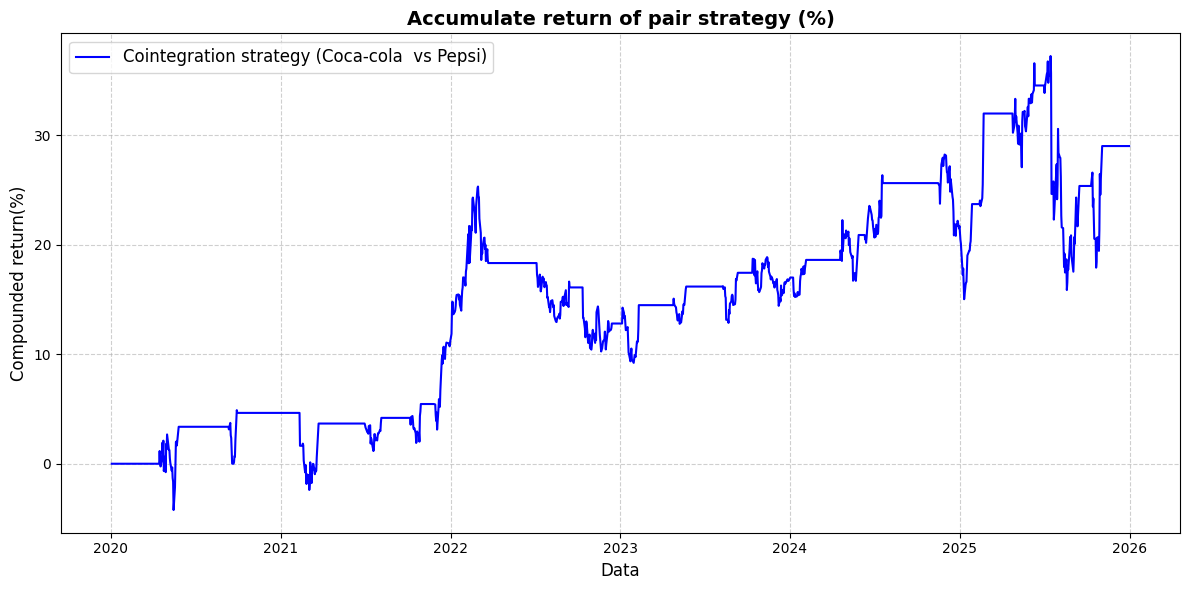

In [19]:
if dictionnary_cointegration["is_cointegrated"]:
  z_score, positions = back_test(dictionnary_cointegration["spread"])
  trade_summary , cumulative_return = analyze_trades(dictionnary_cointegration["spread"], positions)
  print("--- Trade Summary ---")
  display(trade_summary.head(10))
else:
  print("Still drifting, let's try the energy giants next!")

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_return.index,
    cumulative_return * 100  ,
    label="Cointegration strategy (Coca-cola  vs Pepsi)",
    color="blue",
    linewidth=1.5,
)
plt.title(
    "Accumulate return of pair strategy (%)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Data", fontsize=12)
plt.ylabel("Compounded return(%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

## Visa and MasterCard
Let's check both technology payment systems, Visa and Master. Since they represent two stocks of the same industry sector, it's feasible their assets are cointegrated

[*********************100%***********************]  2 of 2 completed


--- Cointegration Test Results ---
ADF Statistic: -5.1953
P-Value: 0.0000
Cointegrated (p <= 0.05): True

--- Trade Summary ---


C:\Users\Usuari\AppData\Local\Temp\ipykernel_27600\3185378370.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spread.dropna())


,entry_date,exit_date,direction,total_return,holding_period
trade_id,,,,,
1,2020-01-02,2020-01-02,Short,0.000000,0
2,2020-04-06,2020-04-06,Short,0.021139,1
3,2020-04-07,2020-04-07,Short,0.019884,1
4,2020-05-19,2020-06-15,Long,0.022303,19
5,2020-06-16,2020-06-16,Short,0.017063,1
7,2020-07-31,2020-07-31,Short,-0.022142,1
8,2020-08-07,2020-10-22,Short,-0.014599,54
9,2020-10-23,2020-10-23,Short,0.012158,1
10,2020-10-30,2021-01-05,Long,-0.016672,45


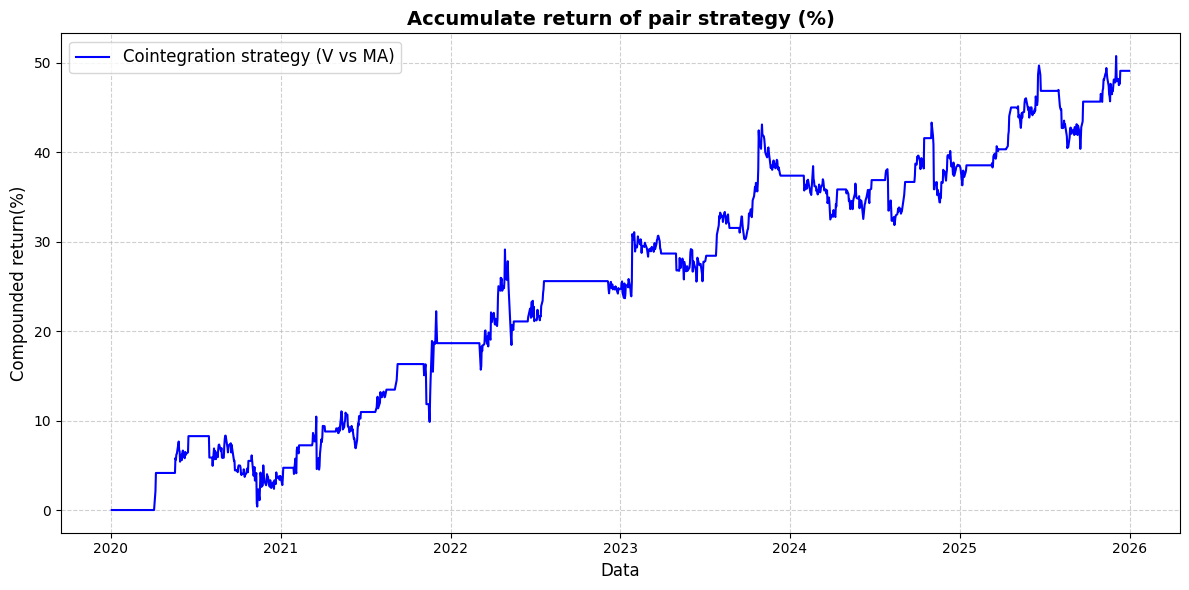

In [21]:
log_X, log_Y = fetch_and_clean_data("V", "MA", "2020-01-01", "2026-01-01")

# Run your cointegration pipeline
results = cointegration_pairs(log_X, log_Y)

if results["is_cointegrated"]:
  z_score, positions = back_test(results["spread"])
  trade_summary , cumulative_return = analyze_trades(results["spread"], positions)
  print("--- Trade Summary ---")
  display(trade_summary.head(10))



plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_return.index,
    cumulative_return * 100  ,
    label="Cointegration strategy (V vs MA)",
    color="blue",
    linewidth=1.5,
)
plt.title(
    "Accumulate return of pair strategy (%)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Data", fontsize=12)
plt.ylabel("Compounded return(%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


In fact p<0.05, both assets are cointegrated ! Let's evaluate the performance of the investment strategy throughout five years

# Issues to improve // Features to add 

-Compute of sharping ratio 
-Evaluate the sensibility of the strategy to changing parameters such as the size of the rolling window, the z_score entry and the z_score exit.

!!This code snippet and analysis were developed with the assistance of AI tools to help refine the methodology, troubleshoot errors, and optimize the workflow. Moreover, this snippet does not constitue any strategy advising.